# Optical coherence tomography: time-domain and spectral-domain A-scans

Optical coherence tomography (OCT) measures depth with light the way
ultrasound does with sound, except that light is far too fast for a stop
watch: a reflector 10 µm deeper returns 67 fs later. OCT measures this
delay by interference with a reference beam. With a broadband source the
two beams interfere only where their paths agree within the coherence
length, a few micrometres, and that gate sets the depth resolution.

A Michelson interferometer splits the light of a superluminescent diode
(SLD) into a reference arm, ending in a mirror at the path $z_R$, and a
sample arm, which focuses into the sample. The sample reflects with the
wavenumber dependent amplitude $r_S(k)$, and the detector sees

$$I(k) = S(k)\,\bigl|r_R\,e^{2ikz_R} + r_S(k)\,e^{2ikz_S}\bigr|^2
       = \underbrace{S\bigl(|r_R|^2 + |r_S|^2\bigr)}_{\text{DC and autocorrelation}}
       + \underbrace{2S\,\mathrm{Re}\bigl(r_R^* r_S\, e^{2ik(z_S - z_R)}\bigr)}_{\text{cross term}}$$

for the power spectrum $S(k)$ of the source and the vacuum wavenumber
$k = 2\pi/\lambda$. A reflector at the depth $z$ contributes
$r_j e^{2ikz}$ to $r_S$, so the cross term is a sum of cosine fringes over
$k$, one per reflector, with a frequency proportional to its depth.

- **Time-domain OCT (TD-OCT)** scans the reference mirror and records the
  integral of $I(k)$ over all $k$ with a photodiode. Fringes appear only
  where $z_R$ matches a reflector within the coherence length; their
  envelope is the A-scan (one depth profile).
- **Spectral-domain OCT (SD-OCT)** keeps the mirror fixed and records
  $I(k)$ with a spectrometer. The A-scan is the Fourier transform of the
  spectrum from $k$ to $z$: all depths at once.

This notebook builds both with `pyoptics.oct`. The sample's $r_S(k)$ comes
from the transfer matrix of `thin_films` (the stacks of notebooks 12 and
13, now hundreds of micrometres thick), with dispersion from the glass
catalogue (`glasses`) and the water formula of `materials`, so multiple
reflections, group delays and dispersion come out by themselves. Each
effect is compared with its analytic value:

1. The **axial resolution** $\frac{2\ln 2}{\pi}\frac{\lambda_0^2}{\Delta\lambda}$
   of a Gaussian spectrum, and the side lobes of spectra that are not
   Gaussian.
2. **A layered sample** in TD and SD: the same A-scan, with the peak
   heights from the Fresnel coefficients and the peak positions at the
   *group* optical depth.
3. **Artefacts of the Fourier transform:** the DC term, the
   autocorrelation of the sample, mirror images, and their removal with a
   quarter wave phase step (full range OCT).
4. The **sensitivity roll-off** with depth from the pixel width and the
   resolution of the spectrometer, against
   $\mathrm{sinc}(z\,\delta k/\pi)\,e^{-z^2w^2/4\ln 2}$.
5. The **SNR advantage** of SD-OCT in a Monte Carlo of shot noise, against
   the number of depths measured in parallel.
6. **Dispersion:** 24 mm of water in the eye blur a 2.6 µm resolution to
   about 50 µm; a glass plate in the reference arm and numerical
   compensation restore it.
7. A **B-scan** of a retina-like phantom with speckle.

The 2D side, the lateral resolution of the focused beam and the confocal
gate, is that of the confocal microscope in notebook 54; the coherence
function of a broadband source and the Michelson interferometer behind it
are in notebook 74.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

from pyoptics import oct as oc
from pyoptics import glasses, sketch
from pyoptics.materials import water_index

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
t_start = time.time()

# all lengths in µm, k = 2 pi/lambda in 1/µm; depths z are single pass optical paths
WL0, DWL = 0.84, 0.05                       # SLD: 840 nm, 50 nm FWHM
K0, W = 2*np.pi/WL0, oc.bandwidth_k(WL0, DWL)
LC = oc.axial_resolution(WL0, DWL)

# spectrometer: 2048 pixels, linear in k, from 765 to 915 nm; each pixel sampled 8 times
N_PIX, OVERSAMPLE = 2048, 8
K_MIN, K_MAX = 2*np.pi/0.915, 2*np.pi/0.765
K_FINE = np.linspace(K_MIN, K_MAX, N_PIX*OVERSAMPLE, endpoint=False)
S_FINE = oc.gaussian_spectrum(K_FINE, K0, W)
K_PIX, S_PIX = oc.spectrometer(K_FINE, S_FINE, N_PIX)
DK = K_PIX[1] - K_PIX[0]
Z_MAX = oc.max_depth(K_PIX)
print("coherence length (axial resolution in air): {:.2f} µm".format(LC))
print("spectrometer: delta k = {:.2e} /µm, maximum depth pi/(2 delta k) = {:.0f} µm".format(DK, Z_MAX))


def n_of(material):
    """Refractive index as a function of the wavelength in µm."""
    if isinstance(material, glasses.Glass):
        return lambda wl: material.n(1000*wl)
    return lambda wl: material(1000*wl)


def group_index(n, wl):
    """n_g = n - lambda dn/dlambda (wavelength in µm)."""
    h = 1e-4
    return n(wl) - wl*(n(wl + h) - n(wl - h))/(2*h)


def sd_scan(r_sample, z_sample, resolution=0.0, r_ref=1.0, n_fft=4*N_PIX, analytic=False):
    """Record an SD-OCT spectrum (fine k grid -> spectrometer) and return z, |A|, raw spectrum.
    The reference arm spectrum (with the sample's mean reflectance) is subtracted."""
    I = oc.spectral_interferogram(K_FINE, S_FINE, r_sample, z_sample=z_sample, r_ref=r_ref)
    _, I_pix = oc.spectrometer(K_FINE, I, N_PIX, resolution)
    background = S_PIX*(abs(r_ref)**2 + np.mean(np.abs(r_sample)**2))
    x = oc.analytic_interferogram(I_pix, background) if analytic else I_pix
    z, A = oc.a_scan(x, K_PIX, background=0 if analytic else background, norm=S_PIX.sum(),
                     n_fft=n_fft)
    return z, A, I_pix

coherence length (axial resolution in air): 6.23 µm
spectrometer: delta k = 6.57e-04 /µm, maximum depth pi/(2 delta k) = 2389 µm


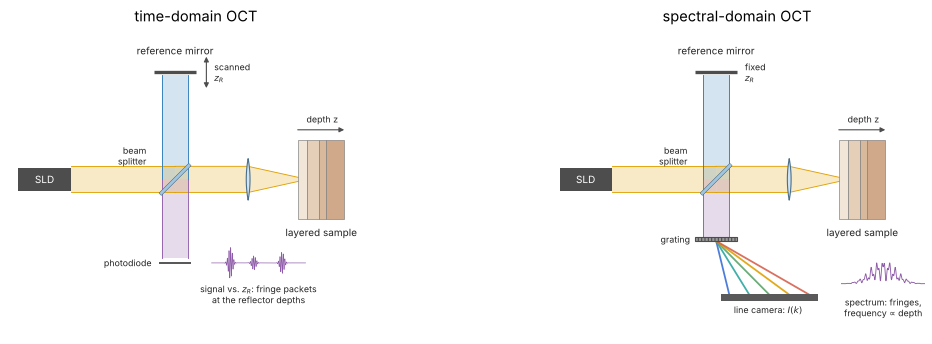

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
sketch.oct_setup(ax[0], "time", title="time-domain OCT")
sketch.oct_setup(ax[1], "spectral", title="spectral-domain OCT")
plt.show()

## 1. Coherence and axial resolution

For a mirror ($r_S = $ const.) at the path difference $\Delta z$, the
TD-OCT signal is
$\int S(k)\,[1 + |r|^2 + 2r\cos(2k\Delta z)]\,dk$: a fringe at the
carrier $2k_0$ under the envelope $|\gamma(\Delta z)|$, the Fourier
transform of $S(k)$ (Wiener–Khinchin, notebook 74). For the Gaussian
spectrum $S = \exp(-4\ln 2\,(k - k_0)^2/w^2)$ the envelope is
$\exp(-\Delta z^2 w^2/4\ln 2)$, with the FWHM

$$l_c = \frac{4\ln 2}{w} = \frac{2\ln 2}{\pi}\,\frac{\lambda_0^2}{\Delta\lambda},$$

6.2 µm in air for the 840 nm SLD with $\Delta\lambda = 50$ nm, and
$l_c/n_g$ inside a sample of group index $n_g$ (4.5 µm in tissue). The
resolution improves with the bandwidth and worsens with the square of the
wavelength: at 1300 nm the same 50 nm give 15 µm. Ultrahigh resolution OCT
uses Ti:sapphire lasers or supercontinuum sources with 100 to 300 nm.

The shape of the spectrum matters too. A flat top spectrum of the same
FWHM has a narrower peak, but with the side lobes of a sinc. Two SLDs side
by side (a common trick to widen the bandwidth) leave a dip in the middle,
and the A-scan gets side lobes at the inverse of the spacing of the two
humps: ghost reflectors at a few coherence lengths.

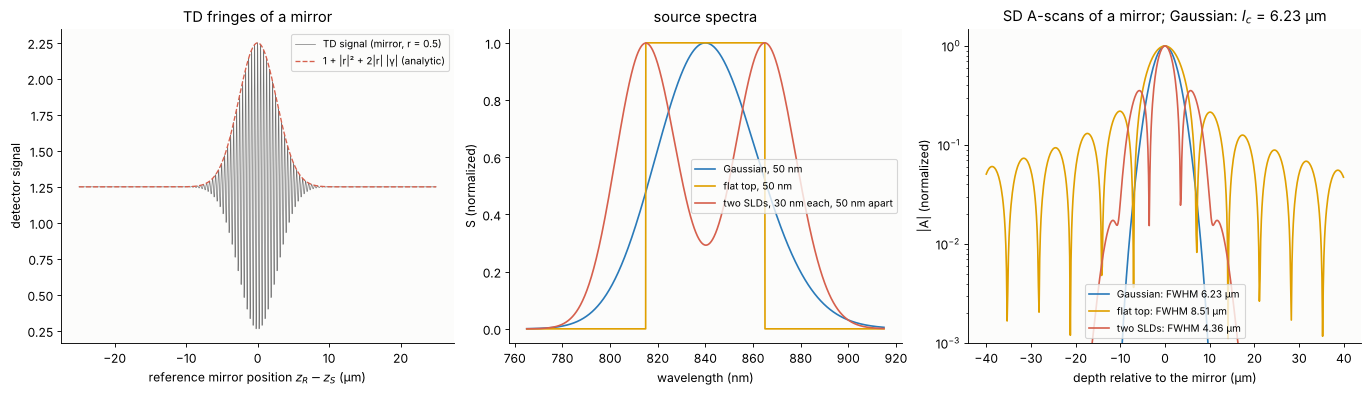

TD envelope FWHM: 6.233 µm, formula: 6.227 µm


In [3]:
z_r = np.arange(-25, 25, 0.02)
td_mirror = oc.time_domain_signal(K_PIX, S_PIX, 0.5, z_r)
env = np.abs(oc.demodulate(td_mirror))

wl_k = 2*np.pi/K_PIX
flat = (np.abs(wl_k - WL0) < DWL/2).astype(float)
two_sld = (oc.gaussian_spectrum(K_PIX, 2*np.pi/0.815, oc.bandwidth_k(0.815, 0.03))
           + oc.gaussian_spectrum(K_PIX, 2*np.pi/0.865, oc.bandwidth_k(0.865, 0.03)))
spectra = {"Gaussian, 50 nm": (S_PIX, BLUE), "flat top, 50 nm": (flat, ORANGE),
           "two SLDs, 30 nm each, 50 nm apart": (two_sld, RED)}

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8), layout="constrained")
ax[0].plot(z_r, td_mirror, color=GREY, lw=0.6, label="TD signal (mirror, r = 0.5)")
ax[0].plot(z_r, 1.25 + 2*0.5*np.exp(-z_r**2*W**2/(4*np.log(2))), "--", color=RED, lw=1.2,
           label="1 + |r|² + 2|r| |γ| (analytic)")
ax[0].set_xlabel("reference mirror position $z_R - z_S$ (µm)")
ax[0].set_ylabel("detector signal")
ax[0].set_title("TD fringes of a mirror")
ax[0].legend(loc="upper right", fontsize=9)
for name, (s, col) in spectra.items():
    ax[1].plot(1000*wl_k, s/s.max(), color=col, label=name)
    z, A = oc.a_scan(oc.spectral_interferogram(K_PIX, s, 0.5, z_sample=300.0), K_PIX,
                     background=s*1.25, norm=s.sum(), n_fft=16*N_PIX)
    a = np.abs(A)/np.abs(A).max()
    sel = np.abs(z - 300) < 40
    ax[2].semilogy(z[sel] - 300, a[sel], color=col,
                   label="{}: FWHM {:.2f} µm".format(name.split(",")[0], oc.fwhm(z[sel], a[sel])))
ax[1].set_xlabel("wavelength (nm)")
ax[1].set_ylabel("S (normalized)")
ax[1].set_title("source spectra")
ax[1].legend(fontsize=9)
ax[2].set_ylim(1e-3, 1.5)
ax[2].set_xlabel("depth relative to the mirror (µm)")
ax[2].set_ylabel("|A| (normalized)")
ax[2].set_title("SD A-scans of a mirror; Gaussian: $l_c$ = {:.2f} µm".format(LC))
ax[2].legend(fontsize=9, loc="lower center")
plt.show()
print("TD envelope FWHM: {:.3f} µm, formula: {:.3f} µm".format(oc.fwhm(z_r, env), LC))

The detector signal oscillates under the envelope predicted from the
spectrum, and the envelope found by Hilbert demodulation
(`oc.demodulate()`) has the FWHM of the formula. With the same FWHM in
wavelength, the flat top spectrum gives a *wider* peak, the sinc
$\sin(wz)/(wz)$ with the FWHM $3.79/w$ = 8.5 µm instead of
$4\ln 2/w$ = 6.2 µm, and side lobes of 22 % (13 dB below the peak) every
$\pi/w$ = 7 µm. The two-SLD source has a narrower core (4.4 µm), but side
lobes of 35 % at $\pm\lambda_0^2/(2\cdot 50\text{ nm}) \approx \pm 7$ µm,
the beat of the two humps 50 nm apart: each reflector gets two ghosts
nearly as strong as a weak real reflector. OCT sources are shaped to be as Gaussian as possible, and the
spectrum is often apodized with a window (at the price of a wider peak).

Now the resolution against the bandwidth for three centre wavelengths of
OCT, each measured from an SD A-scan:

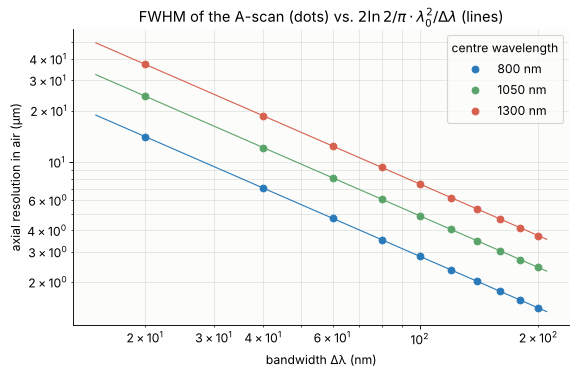

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.8))
dwl = np.linspace(0.02, 0.2, 10)
for wl0, col in ((0.8, BLUE), (1.05, GREEN), (1.3, RED)):
    k0, measured = 2*np.pi/wl0, []
    for d in dwl:
        w = oc.bandwidth_k(wl0, d)
        k = np.linspace(k0 - 4*w, k0 + 4*w, 2048, endpoint=False)
        s = oc.gaussian_spectrum(k, k0, w)
        z, A = oc.a_scan(oc.spectral_interferogram(k, s, 0.5, z_sample=200.0), k, background=s*1.25,
                         n_fft=32*2048)
        measured.append(oc.fwhm(z, np.abs(A)*(z > 0)))
    dd = np.linspace(0.015, 0.21, 200)
    ax.loglog(1000*dd, oc.axial_resolution(wl0, dd), color=col, lw=1)
    ax.loglog(1000*dwl, measured, "o", color=col, label="{:.0f} nm".format(1000*wl0))
ax.set_xlabel("bandwidth Δλ (nm)")
ax.set_ylabel("axial resolution in air (µm)")
ax.set_title("FWHM of the A-scan (dots) vs. $2\\ln 2/\\pi\\cdot\\lambda_0^2/\\Delta\\lambda$ (lines)")
ax.legend(title="centre wavelength")
ax.grid(True, which="both", alpha=0.3)
plt.show()

A small subtlety: $\Delta\lambda$ and $w = \Delta k$ are only related by
$w = 2\pi\Delta\lambda/\lambda_0^2$ to first order. The spectra here are
Gaussian in $k$; a spectrum that is Gaussian in $\lambda$ is slightly
asymmetric in $k$, which changes the resolution by much less than a
percent for these bandwidths.

## 2. A layered sample, time domain and spectral domain

The sample is a stack, built with `thin_films` like the coatings of
notebook 12, but on the scale of an OCT: a cover glass of 150 µm N-BK7
(Sellmeier dispersion from the Schott catalogue) on three tissue-like
layers ($n$ = 1.38, 1.42, 1.36) on a substrate of $n$ = 1.40.
`oc.stack_reflection()` evaluates `thin_films.r_t_coeffs()` for every
wavenumber of the spectrometer: $r_S(k)$ holds all reflections, with all
multiple reflections, and the dispersion of the glass.

Without multiple reflections, interface $j$ returns the amplitude
$r_j \prod_{i<j}(1 - r_i^2)$: its Fresnel coefficient times the round trip
transmission of the interfaces above it (`oc.single_reflection_amplitudes()`).
It appears at the optical depth $\sum_{i<j} n_{g,i}\,t_i$, with the
**group index** $n_g = n - \lambda\,dn/d\lambda$, because the A-scan
locates the envelope, which travels with the group velocity. For N-BK7 at
840 nm, $n = 1.510$ but $n_g = 1.525$: a 150 µm cover glass appears
2.3 µm thicker than with the phase index.

r_S(k) at 16384 wavenumbers in 1.2 s
N-BK7 at 840 nm: n = 1.5100, n_g = 1.5252


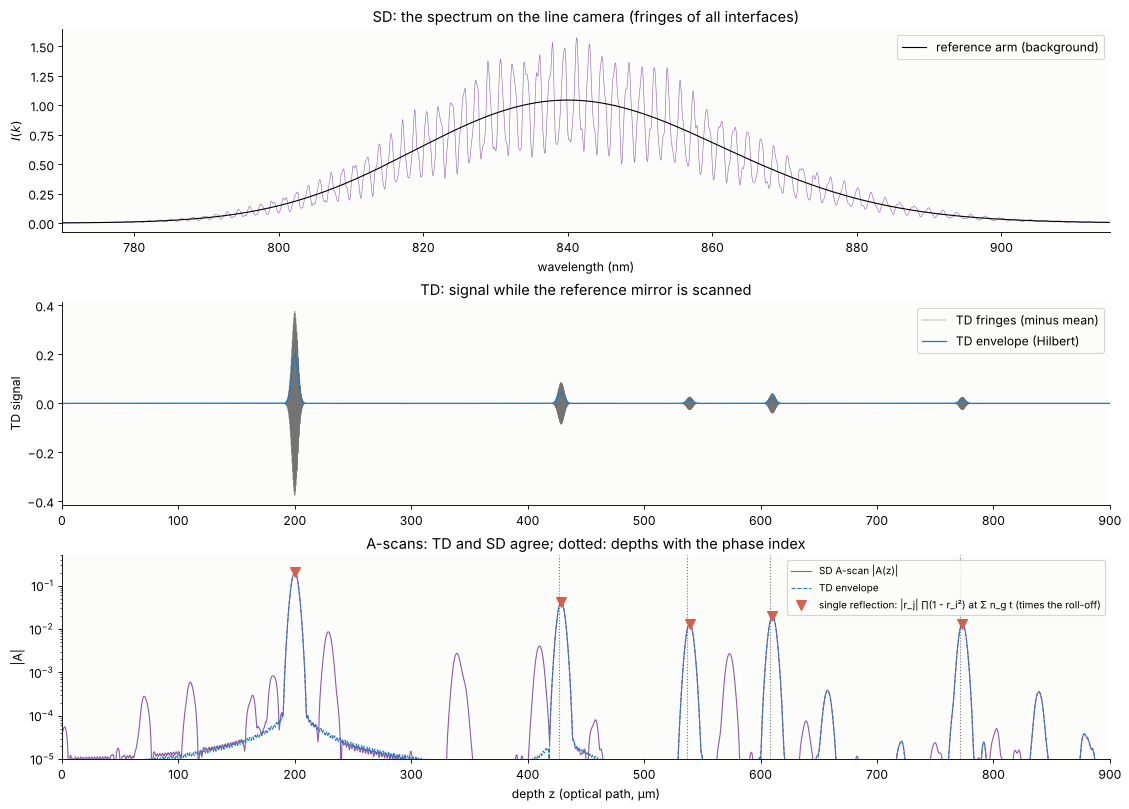

peak   depth (µm)   |A|        predicted depth, amplitude
         70.58    0.00028       (not an interface)
        110.25    0.00060       (not an interface)
        163.91    0.00030       (not an interface)
        180.83    0.00083       (not an interface)
        200.08    0.20253      200.00  0.20261
        228.66    0.00871       (not an interface)
        339.49    0.00276       (not an interface)
        410.07    0.00411       (not an interface)
        428.73    0.04254      428.78  0.04256
        538.98    0.01335      539.18  0.01338
        573.40    0.00273       (not an interface)
        610.14    0.02010      610.18  0.02010
        657.39    0.00038       (not an interface)
        773.47    0.01325      773.38  0.01327
        838.80    0.00036       (not an interface)
       1002.13    0.00024       (not an interface)


In [5]:
bk7 = glasses.get("N-BK7")
n_bk7 = n_of(bk7)
layers = [n_bk7, 1.38, 1.42, 1.36]
thick = [150.0, 80.0, 50.0, 120.0]
n_sub = 1.40
Z_TOP = 200.0                               # optical path difference to the top surface

t0 = time.time()
r_stack = oc.stack_reflection(K_FINE, layers, thick, 1.0, n_sub)
print("r_S(k) at {} wavenumbers in {:.1f} s".format(len(K_FINE), time.time() - t0))

n_c = [n_bk7(WL0), 1.38, 1.42, 1.36]
ng_c = [group_index(n_bk7, WL0), 1.38, 1.42, 1.36]
z_if, amp_if = oc.single_reflection_amplitudes(n_c, thick, 1.0, n_sub, group_index=ng_c)
z_phase, _ = oc.single_reflection_amplitudes(n_c, thick, 1.0, n_sub)
print("N-BK7 at 840 nm: n = {:.4f}, n_g = {:.4f}".format(n_c[0], ng_c[0]))

# time domain: scan the reference over 0 .. 900 µm in steps of lambda/16
z_r = np.arange(0, 900, WL0/16)
_, r_pix = oc.spectrometer(K_FINE, r_stack.real, N_PIX)
_, r_pix_i = oc.spectrometer(K_FINE, r_stack.imag, N_PIX)
td = oc.time_domain_signal(K_PIX, S_PIX, r_pix + 1j*r_pix_i, z_r, z_sample=Z_TOP)
td_env = np.abs(oc.demodulate(td))
# spectral domain
z, A, I_pix = sd_scan(r_stack, Z_TOP)

fig, ax = plt.subplots(3, 1, figsize=(14, 10), layout="constrained")
ax[0].plot(1000*2*np.pi/K_PIX, I_pix, color=PURPLE, lw=0.5)
ax[0].plot(1000*2*np.pi/K_PIX, S_PIX*(1 + np.mean(np.abs(r_stack)**2)), color="k", lw=1,
           label="reference arm (background)")
ax[0].set_xlabel("wavelength (nm)")
ax[0].set_ylabel("$I(k)$")
ax[0].set_title("SD: the spectrum on the line camera (fringes of all interfaces)")
ax[0].legend(loc="upper right")
ax[0].set_xlim(770, 915)
ax[1].plot(z_r, td - td.mean(), color=GREY, lw=0.4, label="TD fringes (minus mean)")
ax[1].plot(z_r, td_env, color=BLUE, lw=1.2, label="TD envelope (Hilbert)")
ax[1].set_xlim(0, 900)
ax[1].set_ylabel("TD signal")
ax[1].legend(loc="upper right")
ax[1].set_title("TD: signal while the reference mirror is scanned")
sel = z > 0
ax[2].semilogy(z[sel], np.abs(A[sel]), color=PURPLE, lw=1, label="SD A-scan |A(z)|")
ax[2].semilogy(z_r, td_env, "--", color=BLUE, lw=1, label="TD envelope")
amp_pred = np.abs(amp_if)*oc.sensitivity_rolloff(Z_TOP + z_if, DK)    # pixel roll-off, section 4
ax[2].plot(Z_TOP + z_if, amp_pred, "v", color=RED, ms=9,
           label="single reflection: |r_j| ∏(1 - r_i²) at Σ n_g t (times the roll-off)")
for zz in Z_TOP + z_phase[1:]:
    ax[2].axvline(zz, color=GREY, ls=":", lw=1)
ax[2].set_ylim(1e-5, 0.5)
ax[2].set_xlim(0, 900)
ax[2].set_xlabel("depth z (optical path, µm)")
ax[2].set_ylabel("|A|")
ax[2].set_title("A-scans: TD and SD agree; dotted: depths with the phase index")
ax[2].legend(loc="upper right", fontsize=9)
plt.show()

peaks, _ = find_peaks(np.abs(A)*(z > 0), height=2e-4, distance=20)
print("peak   depth (µm)   |A|        predicted depth, amplitude")
for p in peaks:
    j = np.argmin(np.abs(Z_TOP + z_if - z[p]))
    pred = "{:8.2f}  {:.5f}".format(Z_TOP + z_if[j], amp_pred[j]) if abs(Z_TOP + z_if[j] - z[p]) < 3 else "   (not an interface)"
    print("      {:8.2f}    {:.5f}    {}".format(z[p], np.abs(A[p]), pred))

Both measurements give the same A-scan: the TD envelope lies on the SD
A-scan, peak for peak. They are related by a Fourier transform; the
information is the same, only the way it is collected differs (section 5).

The five interfaces appear where the group indices put them (the dotted
lines show where the phase index would put the deeper ones, 2.3 µm too
shallow), with the heights of the single reflection formula to better
than 1 % once the slight roll-off of the spectrometer pixels (section 4,
4 % at 770 µm) is included: the top of the cover glass reflects 4 % in
power ($|r| = 0.2$), the glass–tissue interface $|r| = 0.043$ and the
tissue interfaces $|r| \approx 0.014$ to $0.02$, 20 to 24 dB below the
surface.

The peaks that match no interface come from the sample, too:

- Eight are the **autocorrelation** of the sample (section 3), at the
  *differences* of the interface depths (71, 110, 164, 181, 229, 339, 410
  and 573 µm), independent of where the sample sits. They appear only in
  the SD A-scan: in TD-OCT the interference of two sample reflectors does
  not depend on $z_R$, and the scanned signal is blind to it. The
  strongest, at 229 µm, is the surface beating with the back of the
  cover glass, $|r_0 r_1| = 0.0087$, as strong as a real interface.
- Three are **multiple reflections**: light that bounces once more
  inside the cover glass (glass–tissue interface, top surface from
  inside, glass–tissue interface again) appears one glass thickness,
  $n_g t$ = 229 µm, below each deeper interface (at 657, 839 and
  1002 µm), with the amplitude
  $\approx (1 - r_0^2)\,r_1^2\,|r_0| = 3.8\cdot 10^{-4}$ for the first. The
  transfer matrix contains all of them; an OCT cannot tell them from a
  real structure, and cover glasses are tilted or index matched to
  suppress them.

## 3. DC term, autocorrelation and mirror images

The Fourier transform of the real spectrum $I(k)$ has three parts:

- **DC term:** $S(k)(|r_R|^2 + |r_S|^2)$ is smooth in $k$, so it
  transforms into a peak at $z = 0$, as wide as the transform of $S$ and
  millions of times stronger than the signal. Subtracting the reference
  spectrum (measured with the sample arm blocked) removes most of it.
- **Autocorrelation:** $|r_S|^2$ contains the interference of the sample
  reflectors with each other, peaks at their *differences* in depth. It
  cannot be subtracted, but it is weak (products of two small sample
  reflections) and stays close to $z = 0$ if the sample is thin.
- **Mirror images:** $2\,\mathrm{Re}(\ldots) = c + c^*$, so every reflector
  appears at $+z$ and at $-z$. A reflector at $-z$ (above zero delay)
  cannot be told from one at $+z$. The sample is therefore placed entirely
  on one side of zero delay, which halves the usable depth range.

A **full range** (complex conjugate resolved) OCT records a second
spectrum with the reference shifted by a quarter wave, $r_R \to r_R e^{i\pi/2}$:
its cross term is $2\,\mathrm{Im}(c)$ instead of $2\,\mathrm{Re}(c)$, and
$(I_0 - B) + i(I_{90} - B) = 2c$ is complex, with a one-sided transform
(`oc.full_range_interferogram()`). Below, the sample is moved so that its
surface lies 100 µm *above* zero delay.

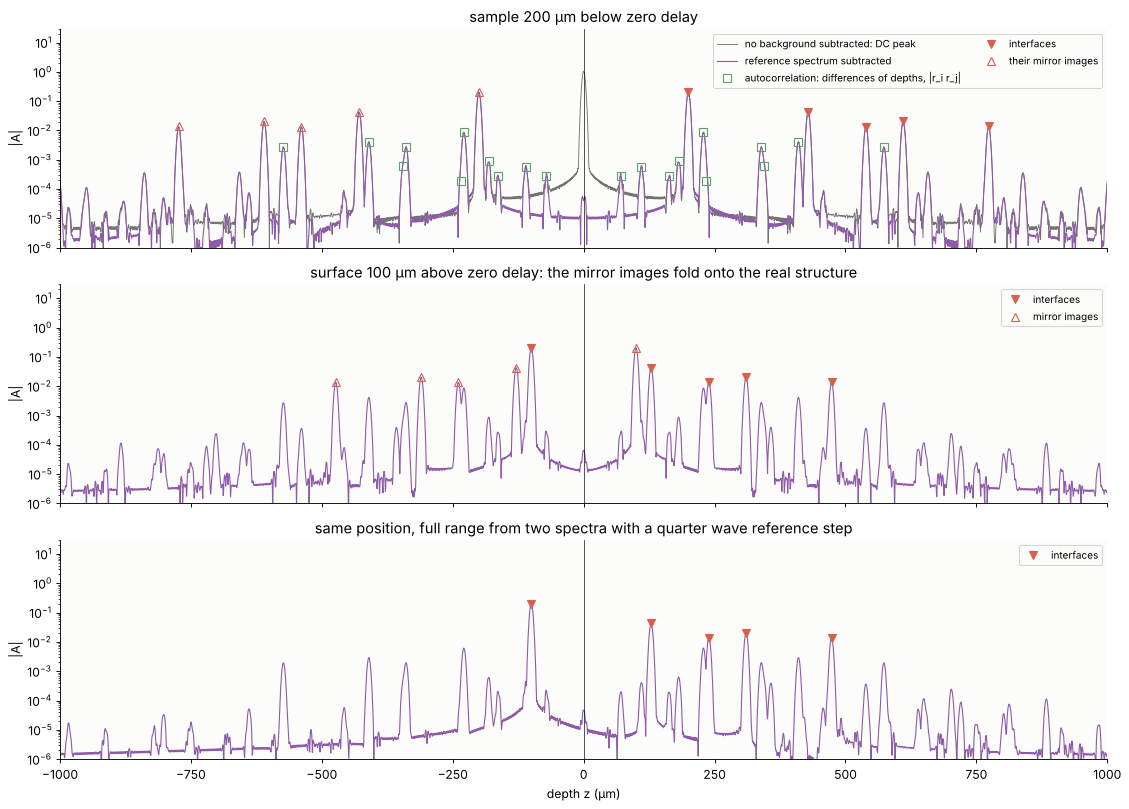

full range: at the mirror position of the third tissue interface 5.8e-06, real peak 2.0e-02 (-71 dB)


In [6]:
fig, ax = plt.subplots(3, 1, figsize=(14, 10), layout="constrained", sharex=True)
z0, A0, I0 = sd_scan(r_stack, Z_TOP)
_, A_dc, _ = sd_scan(r_stack, Z_TOP, n_fft=4*N_PIX)
I_raw = oc.spectral_interferogram(K_FINE, S_FINE, r_stack, z_sample=Z_TOP)
_, I_raw_pix = oc.spectrometer(K_FINE, I_raw, N_PIX)
_, A_raw = oc.a_scan(I_raw_pix, K_PIX, background=0, norm=S_PIX.sum(), n_fft=4*N_PIX)
ax[0].semilogy(z0, np.abs(A_raw), color=GREY, lw=0.8, label="no background subtracted: DC peak")
ax[0].semilogy(z0, np.abs(A0), color=PURPLE, lw=1, label="reference spectrum subtracted")
auto_z = np.abs(np.subtract.outer(z_if, z_if))[np.triu_indices(5, 1)]
auto_a = np.abs(np.multiply.outer(amp_if, amp_if))[np.triu_indices(5, 1)]
ax[0].plot(auto_z, auto_a, "s", mfc="none", color=GREEN, ms=8,
           label="autocorrelation: differences of depths, |r_i r_j|")
ax[0].plot(-auto_z, auto_a, "s", mfc="none", color=GREEN, ms=8)
ax[0].plot(Z_TOP + z_if, np.abs(amp_if), "v", color=RED, ms=8, label="interfaces")
ax[0].plot(-(Z_TOP + z_if), np.abs(amp_if), "^", color=RED, ms=8, mfc="none", label="their mirror images")
ax[0].set_title("sample 200 µm below zero delay")
ax[0].legend(loc="upper right", fontsize=9, ncol=2)

Z_LOW = -100.0
z1, A1, _ = sd_scan(r_stack, Z_LOW)
ax[1].semilogy(z1, np.abs(A1), color=PURPLE, lw=1)
ax[1].plot(Z_LOW + z_if, np.abs(amp_if), "v", color=RED, ms=8, label="interfaces")
ax[1].plot(-(Z_LOW + z_if), np.abs(amp_if), "^", color=RED, ms=8, mfc="none", label="mirror images")
ax[1].set_title("surface 100 µm above zero delay: the mirror images fold onto the real structure")
ax[1].legend(loc="upper right", fontsize=9)

I_0 = oc.spectral_interferogram(K_FINE, S_FINE, r_stack, z_sample=Z_LOW)
I_90 = oc.spectral_interferogram(K_FINE, S_FINE, r_stack, z_sample=Z_LOW, r_ref=1j)
_, I_0p = oc.spectrometer(K_FINE, I_0, N_PIX)
_, I_90p = oc.spectrometer(K_FINE, I_90, N_PIX)
bg = S_PIX*(1 + np.mean(np.abs(r_stack)**2))
z2, A2 = oc.a_scan(oc.full_range_interferogram(I_0p, I_90p, bg), K_PIX, background=0,
                   norm=S_PIX.sum(), n_fft=4*N_PIX)
ax[2].semilogy(z2, np.abs(A2), color=PURPLE, lw=1)
ax[2].plot(Z_LOW + z_if, np.abs(amp_if), "v", color=RED, ms=8, label="interfaces")
ax[2].set_title("same position, full range from two spectra with a quarter wave reference step")
ax[2].legend(loc="upper right", fontsize=9)
for a in ax:
    a.set_ylim(1e-6, 30)
    a.set_ylabel("|A|")
    a.axvline(0, color="k", lw=0.6)
ax[2].set_xlim(-1000, 1000)
ax[2].set_xlabel("depth z (µm)")
plt.show()
i_m = np.argmin(np.abs(z2 - (-(Z_LOW + z_if[3]))))
print("full range: at the mirror position of the third tissue interface {:.1e}, "
      "real peak {:.1e} ({:.0f} dB)".format(np.abs(A2[i_m]), np.interp(Z_LOW + z_if[3], z2, np.abs(A2)),
      20*np.log10(np.abs(A2[i_m])/np.interp(Z_LOW + z_if[3], z2, np.abs(A2)))))

Without subtracting the background, the DC peak at $z = 0$ (height
$|r_R|^2 + \overline{|r_S|^2} \approx 1$ in these units) is 25 times the
surface peak and 100 times the tissue interfaces, and its flanks cover the
first 50 µm. For a real tissue sample with reflectances of $10^{-5}$ to
$10^{-10}$ the ratio is millions. With the reference spectrum
subtracted, the autocorrelation peaks remain: at the differences of the
interface depths (open squares, heights $|r_i r_j|$), symmetric about
zero. The strongest pairs involve the surface, which is why they repeat
the structure of the sample shifted by its distance from zero delay.

With the surface 100 µm above zero delay, every interface has a mirror
image, and the cover glass and the tissue below are folded onto each
other: from the A-scan alone it is impossible to say which peaks are real.
The quarter wave step resolves this: the complex interferogram has no
mirror images (what is left at their positions is the noise floor of the
windowless transform, about 70 dB down). The peaks that remain at
negative depths are the autocorrelation: it sits in the DC term, which is
the same in both spectra, and survives the phase step (a third spectrum
with the reference shifted by half a wave would remove it). In practice
the step is made with a piezo mirror, an electro-optic modulator or a
3×3 fibre coupler, and it is a quarter wave only at one wavelength; the
error at the edges of the spectrum leaves mirror images suppressed by
20 to 40 dB instead of completely.

## 4. Sensitivity roll-off

A reflector at the depth $z$ modulates the spectrum with the period
$\pi/z$ in $k$. A spectrometer with the pixel spacing $\delta k$ samples
this fringe only up to $z_\text{max} = \pi/(2\delta k) = \lambda_0^2/(4\delta\lambda)$,
2.4 mm here; deeper reflectors alias back into the range. Long before
that the fringes are washed out, because every pixel averages over the
width $\delta k$ and the optics blur the spectrum with a resolution $w_s$
(the image of the slit or fibre core on the camera). The fringe amplitude
is multiplied by the Fourier transforms of both,

$$R(z) = \mathrm{sinc}\!\left(\frac{z\,\delta k}{\pi}\right)\,
         \exp\!\left(-\frac{z^2 w_s^2}{4\ln 2}\right),$$

the **sensitivity roll-off** (`oc.sensitivity_rolloff()`). The pixels alone
give $2/\pi$, $-3.9$ dB, at $z_\text{max}$; a resolution of two pixels
makes it $-8.6$ dB at half and $-35$ dB at the full depth range. The simulation below moves a mirror through the
depth range, records it with spectrometers of three resolutions on the
finely sampled $k$ grid, and measures the peak height.

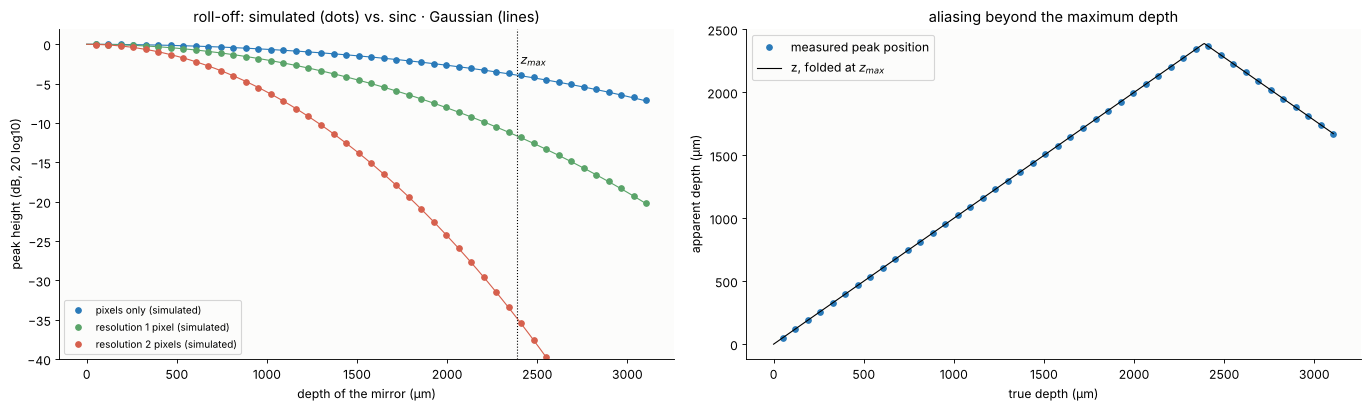

R(z) at 1195 µm: pixels only -0.9 dB, 2 pixel resolution -8.6 dB
R(z) at 2389 µm: pixels only -3.9 dB, 2 pixel resolution -34.8 dB


In [7]:
depths = np.linspace(50, 1.3*Z_MAX, 45)
fig, ax = plt.subplots(1, 2, figsize=(17, 5), layout="constrained")
zz = np.linspace(0, 1.3*Z_MAX, 600)
for res_pix, col in ((0.0, BLUE), (1.0, GREEN), (2.0, RED)):
    res = res_pix*DK
    peak, where = [], []
    for d in depths:
        z, A, _ = sd_scan(0.05, d, resolution=res, n_fft=4*N_PIX)
        sel = z > 20
        i = np.argmax(np.abs(A)*sel)
        peak.append(np.abs(A[i])/0.05)
        where.append(z[i])
    lab = "pixels only" if res_pix == 0 else "resolution {:.0f} pixel{}".format(res_pix, "s"*(res_pix > 1))
    ax[0].plot(depths, 20*np.log10(peak), "o", color=col, ms=5, label=lab + " (simulated)")
    ax[0].plot(zz, 20*np.log10(np.abs(oc.sensitivity_rolloff(zz, DK, res))), color=col, lw=1)
    if res_pix == 0:
        ax[1].plot(depths, where, "o", color=col, ms=5, label="measured peak position")
ax[0].axvline(Z_MAX, color="k", ls=":", lw=1)
ax[0].text(Z_MAX, -1, " $z_{max}$", va="top")
ax[0].set_xlabel("depth of the mirror (µm)")
ax[0].set_ylabel("peak height (dB, 20 log10)")
ax[0].set_ylim(-40, 2)
ax[0].set_title("roll-off: simulated (dots) vs. sinc · Gaussian (lines)")
ax[0].legend(fontsize=9, loc="lower left")
ax[1].plot(zz, np.where(zz < Z_MAX, zz, 2*Z_MAX - zz), color="k", lw=1, label="z, folded at $z_{max}$")
ax[1].set_xlabel("true depth (µm)")
ax[1].set_ylabel("apparent depth (µm)")
ax[1].set_title("aliasing beyond the maximum depth")
ax[1].legend()
plt.show()
for zt in (0.5*Z_MAX, Z_MAX):
    print("R(z) at {:.0f} µm: pixels only {:.1f} dB, 2 pixel resolution {:.1f} dB".format(
        zt, 20*np.log10(oc.sensitivity_rolloff(zt, DK)), 20*np.log10(oc.sensitivity_rolloff(zt, DK, 2*DK))))

The simulated peaks follow the analytic roll-off to a fraction of a dB
over the whole range, and beyond $z_\text{max}$ the mirror reappears at
$2z_\text{max} - z$ while the roll-off continues: a deep reflector folds
back into the image weakened, but not removed. This is why SD-OCT images
are brightest just below zero delay, why the region of interest is placed
there, and why the spectrometer optics are designed for a spot of about
one pixel. Swept-source OCT replaces the spectrometer by a laser that
sweeps its wavelength; its roll-off is set by the instantaneous line width
of the laser and is much slower.

## 5. Why spectral domain: the SNR advantage

TD-OCT spends the time of an A-scan at each depth only briefly: while the
reference mirror passes a reflector, during a fraction $l_c/L$ of the
scan over the depth range $L$. SD-OCT collects the fringes of all depths
for the whole exposure. With shot noise from the reference light (the
usual limit), the signal-to-noise ratio of a reflector that returns $N_S$
photons per A-scan is

$$\mathrm{SNR}_\text{SD} = N_S, \qquad
  \mathrm{SNR}_\text{TD} = N_S\,\frac{\int|\gamma(z)|^2\,dz}{L}
  = N_S\,\frac{\sqrt{\pi/8\ln 2}\;l_c}{L}$$

(both for optimal, matched filter detection), a ratio of about the number
of resolvable depths: Leitgeb et al., de Boer et al. and Choma et al.
(2003) found 20 to 30 dB, which made video rate OCT possible. The Monte
Carlo below gives both systems the same photons: $10^{10}$ reference
photons per A-scan and a reflector of reflectance $10^{-5}$
($N_S = 10^5$). The SD camera counts Poisson photons in its 2048 pixels;
the TD photodiode counts them at 24 000 mirror positions over the same
2.4 mm, and its fringes are demodulated and filtered with the coherence
envelope (the matched filter).

SNR SD: 100601 (50.0 dB), theory N_S = 100000
SNR TD: 198 (23.0 dB), theory 196
gain SD/TD: 508 (27.1 dB), theory L/(0.753 l_c) = 510 (27.1 dB)


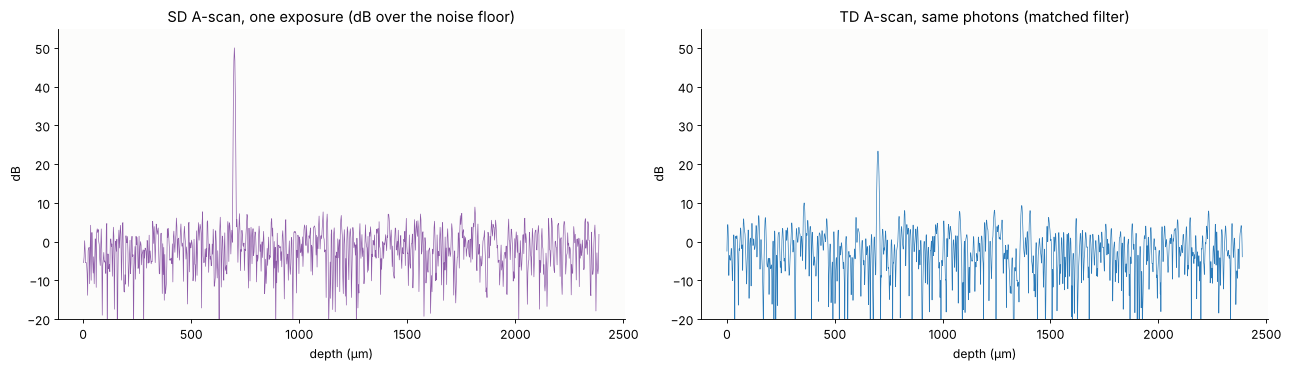

In [8]:
rng = np.random.default_rng(82)
N_R, R_S = 1e10, 1e-5
a_s = np.sqrt(R_S)
z_s = 300*np.pi/(N_PIX*DK)                   # on an FFT bin
mean_sd = oc.spectral_interferogram(K_PIX, S_PIX, a_s, z_sample=z_s)/S_PIX.sum()*N_R
bg_sd = N_R*S_PIX/S_PIX.sum()*(1 + R_S)
dz_td = WL0/8
z_td = np.arange(0, Z_MAX, dz_td)
mean_td = oc.time_domain_signal(K_PIX, S_PIX, a_s, z_td, z_sample=z_s)*N_R/len(z_td)
h = oc.coherence_envelope(np.arange(-4*LC, 4*LC + dz_td/2, dz_td), W)

snr_sd, snr_td = [], []
for trial in range(40):
    z, A = oc.a_scan(rng.poisson(mean_sd).astype(float), K_PIX, background=bg_sd, norm=1.0)
    i = np.argmin(np.abs(z - z_s))
    noise = np.abs(A[(z > 30) & (np.abs(z - z_s) > 30)])**2
    snr_sd.append((np.abs(A[i])**2, noise.mean()))
    c = rng.poisson(mean_td).astype(float)
    out = np.convolve((c - c.mean())*np.exp(2j*K0*z_td), h, mode="same")
    j = np.argmin(np.abs(z_td - z_s))
    snr_td.append((np.abs(out[j])**2, np.mean(np.abs(out[np.abs(z_td - z_s) > 60])**2)))
snr_sd, snr_td = np.array(snr_sd), np.array(snr_td)
SNR_SD = snr_sd[:, 0].mean()/snr_sd[:, 1].mean()
SNR_TD = snr_td[:, 0].mean()/snr_td[:, 1].mean()
ratio = oc.sd_td_snr_ratio(Z_MAX, LC)
print("SNR SD: {:.0f} ({:.1f} dB), theory N_S = {:.0f}".format(SNR_SD, 10*np.log10(SNR_SD), R_S*N_R))
print("SNR TD: {:.0f} ({:.1f} dB), theory {:.0f}".format(SNR_TD, 10*np.log10(SNR_TD), R_S*N_R/ratio))
print("gain SD/TD: {:.0f} ({:.1f} dB), theory L/(0.753 l_c) = {:.0f} ({:.1f} dB)".format(
    SNR_SD/SNR_TD, 10*np.log10(SNR_SD/SNR_TD), ratio, 10*np.log10(ratio)))

fig, ax = plt.subplots(1, 2, figsize=(16, 4.5), layout="constrained")
z, A = oc.a_scan(rng.poisson(mean_sd).astype(float), K_PIX, background=bg_sd, norm=1.0)
ax[0].plot(z[z > 0], 10*np.log10(np.abs(A[z > 0])**2/snr_sd[:, 1].mean()), color=PURPLE, lw=0.6)
ax[0].set_title("SD A-scan, one exposure (dB over the noise floor)")
c = rng.poisson(mean_td).astype(float)
out = np.convolve((c - c.mean())*np.exp(2j*K0*z_td), h, mode="same")
ax[1].plot(z_td, 10*np.log10(np.abs(out)**2/snr_td[:, 1].mean()), color=BLUE, lw=0.6)
ax[1].set_title("TD A-scan, same photons (matched filter)")
for a in ax:
    a.set_xlabel("depth (µm)")
    a.set_ylabel("dB")
    a.set_ylim(-20, 55)
plt.show()

The Monte Carlo reproduces both formulas: SD-OCT detects the reflector at
50 dB, TD-OCT with the same photons at about 23 dB, a gain of 27 dB, the
ratio of the depth range to the coherence length. The gain is not free:
the SD camera must have 2048 pixels, each with its own read noise, which
limits SD-OCT at low reference power, and the roll-off of section 4
eats part of the gain for deep reflectors.

## 6. Dispersion: the eye's 24 mm of water

Unbalanced dispersion between the arms adds a phase $\phi(k)$ to the
cross term. Expanded around $k_0$,

$$\phi(k) = \phi_0 + \phi_1(k - k_0) + \frac{1}{2}\phi_2(k - k_0)^2 + \frac{1}{6}\phi_3(k - k_0)^3:$$

$\phi_1$ is the extra group delay (it only shifts the A-scan, and the reference arm
length is adjusted to it), $\phi_2$ broadens the peak symmetrically and
$\phi_3$ gives it an asymmetric tail. For a Gaussian spectrum the width
grows by

$$\frac{l_c'}{l_c} = \sqrt{1 + \left(\frac{\phi_2 w^2}{8\ln 2}\right)^2}$$

(`oc.dispersion_broadening()`), and the peak drops by the square root of
this factor. The effect scales with the square of the bandwidth, so it
matters most for ultrahigh resolution systems. In retinal OCT the sample
arm passes through about 24 mm of ocular media, mostly water. For a
Ti:sapphire-like source at 840 nm with 120 nm bandwidth ($l_c$ = 2.6 µm),
$\phi(k) = 2kn_w(k)L$ from the Sellmeier formula of water (Daimon and
Masumura) gives the coefficients below. The retina is modelled as a stack
of five layers in water ($n$ = 1.38 to 1.40, the RPE slightly absorbing).

24 mm water, round trip: group delay phi_1/2 = 32200 µm (n_g = 1.3417), phi_2 = 90.4 µm², phi_3 = 48.4 µm³
1 mm N-BK7, round trip: phi_2 = 7.37 µm², phi_3 = 1.81 µm³
N-BK7 that matches phi_2: 12.28 mm, leaves phi_3 = 26.2 µm³
predicted broadening by the water: x18.6 (2.6 -> 48.4 µm)


numerical compensation found phi_2 = 89.0 µm², phi_3 = 48.5 µm³ (water: 90.4, 48.4)


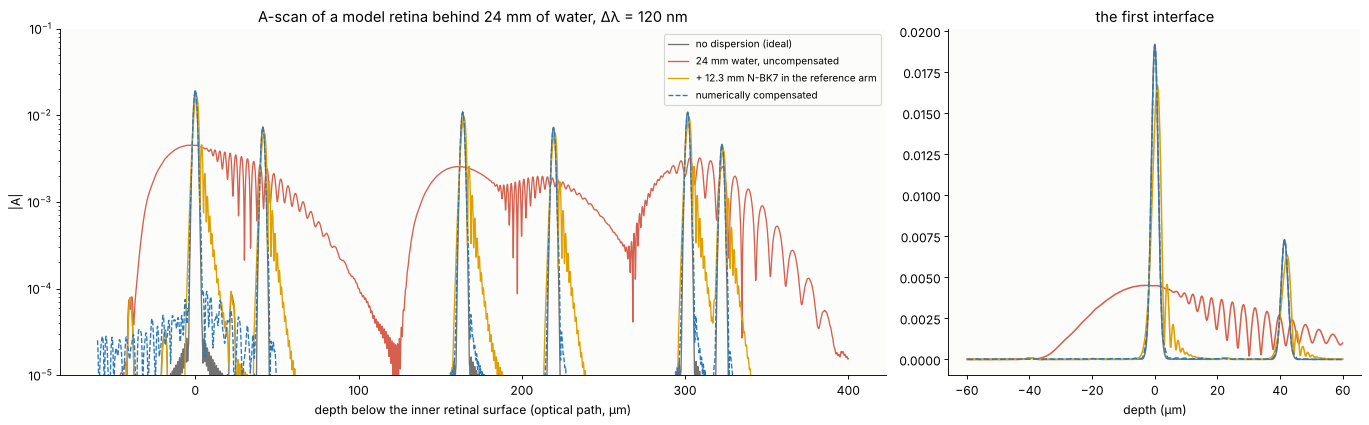

no dispersion (ideal)                         FWHM   2.60 µm
24 mm water, uncompensated                    FWHM  42.44 µm
+ 12.3 mm N-BK7 in the reference arm          FWHM   3.31 µm
numerically compensated                       FWHM   2.63 µm
mirror, phi_2 only: FWHM 48.39 µm, peak 0.0232; formula 48.39 µm, 0.0232


In [9]:
WL0B, DWLB = 0.84, 0.12
K0B, WB = 2*np.pi/WL0B, oc.bandwidth_k(WL0B, DWLB)
LCB = oc.axial_resolution(WL0B, DWLB)
KB = np.linspace(2*np.pi/1.02, 2*np.pi/0.70, 4096, endpoint=False)
SB = oc.gaussian_spectrum(KB, K0B, WB)
n_w = n_of(water_index)
L_EYE = 24000.0

fit = np.abs(KB - K0B) < 2*WB
phi_w = oc.dispersion_coefficients(KB[fit], oc.round_trip_phase(KB[fit], n_w, L_EYE), K0B, order=5)
phi_g = oc.dispersion_coefficients(KB[fit], oc.round_trip_phase(KB[fit], n_bk7, 1000.0), K0B, order=5)
L_BK7 = 1000.0*phi_w[2]/phi_g[2]
print("24 mm water, round trip: group delay phi_1/2 = {:.0f} µm (n_g = {:.4f}), "
      "phi_2 = {:.1f} µm², phi_3 = {:.1f} µm³".format(phi_w[1]/2, phi_w[1]/2/L_EYE, phi_w[2], phi_w[3]))
print("1 mm N-BK7, round trip: phi_2 = {:.2f} µm², phi_3 = {:.2f} µm³".format(phi_g[2], phi_g[3]))
print("N-BK7 that matches phi_2: {:.2f} mm, leaves phi_3 = {:.1f} µm³".format(
    L_BK7/1000, phi_w[3] - phi_g[3]*L_BK7/1000))
print("predicted broadening by the water: x{:.1f} ({:.1f} -> {:.1f} µm)".format(
    oc.dispersion_broadening(phi_w[2], WB), LCB, LCB*oc.dispersion_broadening(phi_w[2], WB)))

retina_n = [1.38, 1.36, 1.39, 1.37, 1.40 + 0.002j]
retina_t = [30.0, 90.0, 40.0, 60.0, 15.0]
r_ret = oc.stack_reflection(KB, retina_n, retina_t, n_w, 1.38)


def linear_part(phase):
    """phi_0 + phi_1 (k - k0) of the Taylor expansion at k0."""
    c = oc.dispersion_coefficients(KB[fit], phase[fit], K0B, order=5)
    return c[0] + c[1]*(KB - K0B)


phase_eye = oc.round_trip_phase(KB, n_w, L_EYE)
phase_eye = phase_eye - linear_part(phase_eye)          # group delay matched by the reference arm
phase_ref = oc.round_trip_phase(KB, n_bk7, L_BK7)
phase_ref = phase_ref - linear_part(phase_ref)
Z_RET = 300.0
cases = {"no dispersion (ideal)": np.zeros_like(KB),
         "24 mm water, uncompensated": phase_eye,
         "+ {:.1f} mm N-BK7 in the reference arm".format(L_BK7/1000): phase_eye - phase_ref}
scans = {}
for name, ph in cases.items():
    I = oc.spectral_interferogram(KB, SB, r_ret*np.exp(1j*ph), z_sample=Z_RET)
    c_int = oc.analytic_interferogram(I, SB*(1 + np.mean(np.abs(r_ret)**2)))
    scans[name] = c_int
found = oc.optimize_dispersion(scans["24 mm water, uncompensated"], KB, K0B, WB, order=3)
print("numerical compensation found phi_2 = {:.1f} µm², phi_3 = {:.1f} µm³ (water: {:.1f}, {:.1f})".format(
    found[0], found[1], phi_w[2], phi_w[3]))
scans["numerically compensated"] = oc.compensate_dispersion(scans["24 mm water, uncompensated"], KB,
                                                            K0B, found)

fig, ax = plt.subplots(1, 2, figsize=(17, 5.2), layout="constrained", gridspec_kw={"width_ratios": [2, 1]})
colours = (GREY, RED, ORANGE, BLUE)
widths = {}
for (name, c_int), col, ls in zip(scans.items(), colours, ("-", "-", "-", "--")):
    z, A = oc.a_scan(c_int, KB, background=0, norm=SB.sum(), n_fft=8*len(KB))
    sel = (z > Z_RET - 60) & (z < Z_RET + 400)
    ax[0].semilogy(z[sel] - Z_RET, np.abs(A[sel]), color=col, ls=ls, lw=1.2, label=name)
    zoom = np.abs(z - Z_RET) < 60
    ax[1].plot(z[zoom] - Z_RET, np.abs(A[zoom]), color=col, ls=ls, lw=1.4)
    widths[name] = oc.fwhm(z[zoom], np.abs(A[zoom]))
ax[0].set_ylim(1e-5, 0.1)
ax[0].set_xlabel("depth below the inner retinal surface (optical path, µm)")
ax[0].set_ylabel("|A|")
ax[0].set_title("A-scan of a model retina behind 24 mm of water, Δλ = 120 nm")
ax[0].legend(fontsize=9, loc="upper right")
ax[1].set_xlabel("depth (µm)")
ax[1].set_title("the first interface")
plt.show()
for name, wdt in widths.items():
    print("{:45s} FWHM {:6.2f} µm".format(name, wdt))
# a lone mirror with only the quadratic phase of the water, against the formula
I = oc.spectral_interferogram(KB, SB, 0.1*np.exp(0.5j*phi_w[2]*(KB - K0B)**2), z_sample=Z_RET)
z, A = oc.a_scan(oc.analytic_interferogram(I, SB*1.01), KB, background=0, norm=SB.sum(), n_fft=8*len(KB))
print("mirror, phi_2 only: FWHM {:.2f} µm, peak {:.4f}; formula {:.2f} µm, {:.4f}".format(
    oc.fwhm(z, np.abs(A)), np.abs(A).max(), LCB*oc.dispersion_broadening(phi_w[2], WB),
    0.1/np.sqrt(oc.dispersion_broadening(phi_w[2], WB))))

The water spreads the 2.6 µm peak over some 45 µm and lowers it by a
factor of four: the thin layers of the retina merge into a smear. For a
lone mirror with only the quadratic term, the width and the height agree
with the formula (48.4 µm, a factor 18.6 wider and $\sqrt{18.6}$ lower);
in the retina the cubic term and the neighbouring layers make the
measured width a little smaller. Two cures:

- **Hardware:** a glass plate in the reference arm with the same $\phi_2$,
  here 12 mm of N-BK7 (in practice a water cell or a matching glass
  pair). This restores the second order exactly, but glass and water
  differ in the third order: 26 µm³ are left over, widen the peaks to
  3.3 µm and give them an asymmetric tail on one side.
- **Numerical:** the dispersion is a known *phase* of the spectral
  interferogram, so it can be removed after the measurement. After a
  Hilbert transform over $k$ (`oc.analytic_interferogram()`), the complex
  spectrum is multiplied by $e^{-i(\phi_2 q^2/2 + \phi_3 q^3/6)}$,
  $q = k - k_0$ (`oc.compensate_dispersion()`). The coefficients need not
  be known: `oc.optimize_dispersion()` maximizes the sharpness
  $\sum\lvert A\rvert^4/(\sum\lvert A\rvert^2)^2$ of the A-scan (Wojtkowski et al. 2004) and
  finds the water's $\phi_2$ and $\phi_3$ from the blurred scan itself
  (to 2 %). The compensated A-scan lies on the ideal one.

Numerical compensation needs the phase of the spectral fringes and works
for SD-OCT and swept-source OCT. Because the dispersion grows with depth
in a dispersive sample, a single correction is exact only at one depth;
for thick samples the correction is made depth dependent.

## 7. A B-scan of a retina-like phantom

A B-scan is a row of A-scans across the sample. Real tissue is not a
stack of smooth interfaces but a volume of random small scatterers. Their
echoes within one coherence volume (lateral beam width times $l_c$)
interfere with random phases: OCT images are covered with **speckle**,
the same grain as in notebook 73. The phantom below has the layers of a
retina near the fovea (nerve fibre layer, plexiform and nuclear layers,
photoreceptors with the bright IS/OS junction, retinal pigment epithelium
and choroid), each filled with point scatterers of its own density and
strength, a foveal pit in which the inner layers thin out, and
attenuation with depth. Each A-scan sums the scatterers within the
Gaussian beam (waist 8 µm) with their amplitudes
$\propto e^{-2(x - x_j)^2/w_0^2}$, the round trip attenuation and the
roll-off of the 2-pixel spectrometer, on the 2048 pixels of the camera;
the A-scans are computed with a Hann window and displayed in dB.

In [10]:
rng = np.random.default_rng(7)
X_SCAN = np.linspace(-1500, 1500, 400)          # lateral positions (µm)
W0 = 8.0
N_TISSUE = 1.38


def boundaries(x):
    """Geometric depths (µm below the vitreous) of the retinal boundaries at the lateral position x."""
    pit = np.exp(-(x/350.0)**2)
    top = 40.0*pit                                         # the pit lowers the inner surface
    one = np.ones_like(pit)
    t = np.array([45*(1 - pit), 70*(1 - 0.9*pit), 35*(1 - 0.7*pit), 25*(1 - 0.5*pit),
                  80 + 20*pit, 12*one, 22*one, 18*one, 400*one])
    return top + np.concatenate((0*one[None], np.cumsum(t, axis=0)))


#            NFL   GCL/IPL  INL   OPL   ONL   IS/OS  OS   RPE  choroid
density = [0.050, 0.030, 0.020, 0.040, 0.010, 0.080, 0.02, 0.10, 0.05]   # scatterers per µm² (x-z)
strength = [1.0, 0.55, 0.25, 0.7, 0.15, 1.6, 0.4, 1.4, 0.6]
MU = 0.0015                                      # attenuation per µm (round trip 2 mu z)

scat_x, scat_z, scat_a = [], [], []
x_lo, x_hi = X_SCAN[0] - 3*W0, X_SCAN[-1] + 3*W0
for j in range(9):
    zb = boundaries(np.linspace(x_lo, x_hi, 2000))
    area = np.trapezoid(zb[j + 1] - zb[j], np.linspace(x_lo, x_hi, 2000))
    n = rng.poisson(density[j]*area)
    xs = rng.uniform(x_lo, x_hi, n)
    b = boundaries(xs)
    zs = b[j] + rng.uniform(0, 1, n)*(b[j + 1] - b[j])
    scat_x.append(xs)
    scat_z.append(zs)
    scat_a.append(strength[j]*np.ones(n))
scat_x, scat_z, scat_a = map(np.concatenate, (scat_x, scat_z, scat_a))
print("{} scatterers".format(len(scat_x)))
RES = 2*DK
win = np.hanning(N_PIX)


def b_scan(z_offset, full_range=False):
    """B-scan of the phantom with its surface at the optical path z_offset; complex A-scans (rows: x)."""
    rows = []
    for x in X_SCAN:
        near = np.abs(scat_x - x) < 3*W0
        z_opt = z_offset + N_TISSUE*scat_z[near]
        amp = 1e-3*scat_a[near]*np.exp(-2*(scat_x[near] - x)**2/W0**2)*np.exp(-2*MU*scat_z[near])
        amp = amp*oc.sensitivity_rolloff(z_opt, DK, RES)*rng.choice([-1.0, 1.0], near.sum())
        r_k = np.exp(2j*np.outer(K_PIX, z_opt)) @ amp           # r_S(k) referred to zero delay
        if full_range:
            I0 = oc.spectral_interferogram(K_PIX, S_PIX, r_k)
            I90 = oc.spectral_interferogram(K_PIX, S_PIX, r_k, r_ref=1j)
            sig = oc.full_range_interferogram(I0, I90, S_PIX*(1 + np.mean(np.abs(r_k)**2)))
            rows.append(oc.a_scan(sig, K_PIX, background=0, window=win, norm=np.sum(S_PIX*win))[1])
        else:
            I = oc.spectral_interferogram(K_PIX, S_PIX, r_k)
            rows.append(oc.a_scan(I, K_PIX, background=S_PIX*(1 + np.mean(np.abs(r_k)**2)), window=win,
                                  norm=np.sum(S_PIX*win))[1])
    z, _ = oc.a_scan(S_PIX, K_PIX)
    return z, np.array(rows)


t0 = time.time()
z_b, B1 = b_scan(150.0)
_, B2 = b_scan(-250.0)
_, B3 = b_scan(-250.0, full_range=True)
print("three B-scans of {} A-scans in {:.0f} s".format(len(X_SCAN), time.time() - t0))

88443 scatterers


three B-scans of 400 A-scans in 135 s


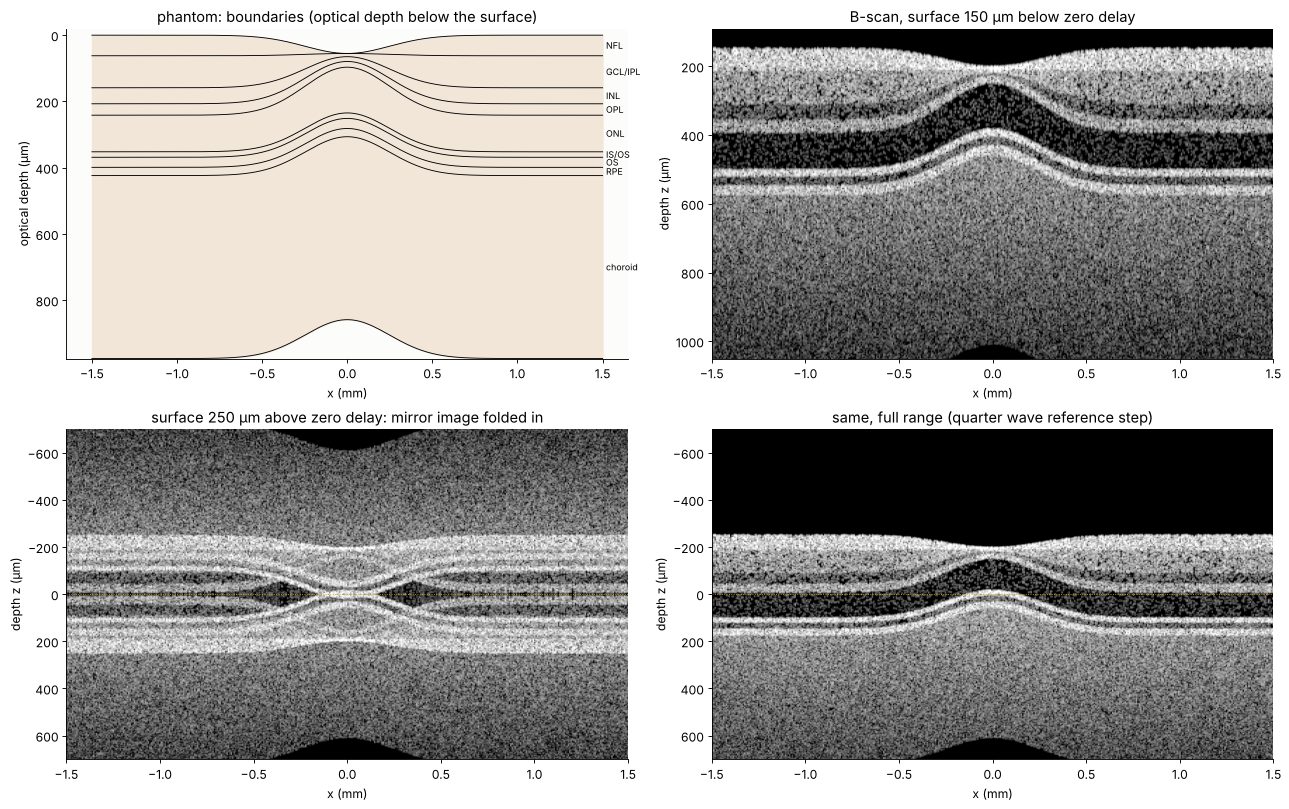

In [11]:
noise = 10**(-4.6)*np.std(np.abs(B1))       # a common display floor
fig, ax = plt.subplots(2, 2, figsize=(16, 10), layout="constrained")
xx = np.linspace(X_SCAN[0], X_SCAN[-1], 600)
bb = boundaries(xx)
for j in range(10):
    ax[0, 0].plot(xx/1000, N_TISSUE*bb[j], color="k", lw=0.8)
ax[0, 0].fill_between(xx/1000, N_TISSUE*bb[0], N_TISSUE*bb[-1], color="#f2e6d8", zorder=0)
names = ["NFL", "GCL/IPL", "INL", "OPL", "ONL", "IS/OS", "OS", "RPE", "choroid"]
for j, nm in enumerate(names):
    zc = N_TISSUE*(bb[j][-1] + bb[j + 1][-1])/2
    ax[0, 0].text(1.52, zc, nm, va="center", fontsize=8)
ax[0, 0].set_ylim(N_TISSUE*bb[-1].max(), -20)
ax[0, 0].set_title("phantom: boundaries (optical depth below the surface)")
ax[0, 0].set_xlabel("x (mm)")
ax[0, 0].set_ylabel("optical depth (µm)")
panels = ((ax[0, 1], B1, 150.0, "B-scan, surface 150 µm below zero delay"),
          (ax[1, 0], B2, -250.0, "surface 250 µm above zero delay: mirror image folded in"),
          (ax[1, 1], B3, -250.0, "same, full range (quarter wave reference step)"))
for a, B, off, title in panels:
    db = 20*np.log10(np.abs(B.T) + 1e-12)
    vmax = np.percentile(db, 99.9)
    a.imshow(db, extent=(X_SCAN[0]/1000, X_SCAN[-1]/1000, z_b[0], z_b[-1]), origin="lower",
             aspect="auto", cmap="gray", vmin=vmax - 45, vmax=vmax)
    a.set_ylim(off + 900 if off > 0 else 700, off - 60 if off > 0 else -700)
    a.axhline(0, color=ORANGE, lw=0.8, ls=":")
    a.set_title(title)
    a.set_xlabel("x (mm)")
    a.set_ylabel("depth z (µm)")
plt.show()

The B-scan shows the phantom as an OCT would: bright bands for the nerve
fibre layer, the plexiform layers, the IS/OS line and the RPE, dark
nuclear layers, the pit at the fovea, and everything grainy with speckle
(each pixel is a random sum of a few scatterers). The choroid fades with
depth because of the attenuation and the roll-off. The structure is
placed below zero delay, as in every SD-OCT. When the reference is moved
so that zero delay falls inside the retina, the part above zero delay is
folded back as an upside down mirror image, overlapping the real one; the
full range scan with the quarter wave step separates the two and shows
the whole retina, with the part above zero delay at negative depths.

## Summary

- **Axial resolution:** the A-scan of a mirror is the coherence function
  $|\gamma|$, the Fourier transform of the source spectrum; for a Gaussian
  its FWHM is $l_c = \frac{2\ln 2}{\pi}\frac{\lambda_0^2}{\Delta\lambda}$
  (`oc.axial_resolution()`), confirmed from 20 to 200 nm at three centre
  wavelengths. Non-Gaussian spectra add side lobes (sinc for a flat top,
  ghost peaks for two SLDs).
- **TD = SD:** time-domain and spectral-domain OCT measure the same A-scan
  (`oc.time_domain_signal()` with `oc.demodulate()` against
  `oc.spectral_interferogram()`, `oc.spectrometer()` and `oc.a_scan()`).
  For a layer stack from the transfer matrix (`oc.stack_reflection()`),
  the peaks sit at the group optical depths $\sum n_g t$ with the heights
  $|r_j|\prod(1 - r_i^2)$ (`oc.single_reflection_amplitudes()`); multiple
  reflections add ghost peaks.
- **Artefacts:** the DC term (removed by subtracting the reference
  spectrum), the autocorrelation at the differences of depths, and the
  mirror images at $-z$, removed by a quarter wave reference step
  (`oc.full_range_interferogram()`).
- **Roll-off:** the spectrometer's pixels and resolution reduce the signal
  with depth as $\mathrm{sinc}(z\delta k/\pi)e^{-z^2w_s^2/4\ln 2}$
  (`oc.sensitivity_rolloff()`), $-3.9$ dB at $z_\text{max} = \pi/2\delta k$
  from the pixels alone; deeper reflectors alias.
- **SNR:** for the same photons, SD-OCT beats TD-OCT by
  $L/(0.753\,l_c)$, 27 dB here (`oc.sd_td_snr_ratio()`, Monte Carlo).
- **Dispersion:** unbalanced $\phi_2$ broadens the peak by
  $\sqrt{1 + (\phi_2 w^2/8\ln 2)^2}$ (`oc.dispersion_broadening()`):
  24 mm of water turn 2.6 µm into about 45 µm at 120 nm bandwidth. A
  12 mm N-BK7 plate matches $\phi_2$ but leaves $\phi_3$; numerical
  compensation (`oc.optimize_dispersion()`, `oc.compensate_dispersion()`)
  recovers both coefficients from the blurred A-scan.
- **B-scan:** scatterers in a layered phantom give the speckled images of
  clinical OCT, with roll-off, attenuation and mirror folding.

In [12]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 143 s


## References

- D. Huang, E. A. Swanson, C. P. Lin, J. S. Schuman, W. G. Stinson, W. Chang, M. R. Hee, T. Flotte, K. Gregory, C. A. Puliafito and J. G. Fujimoto, "Optical coherence tomography", Science 254, 1178-1181 (1991).
- A. F. Fercher, C. K. Hitzenberger, G. Kamp and S. Y. El-Zaiat, "Measurement of intraocular distances by backscattering spectral interferometry", Opt. Commun. 117, 43-48 (1995).
- A. F. Fercher, W. Drexler, C. K. Hitzenberger and T. Lasser, "Optical coherence tomography - principles and applications", Rep. Prog. Phys. 66, 239-303 (2003).
- J. A. Izatt and M. A. Choma, "Theory of optical coherence tomography", in W. Drexler and J. G. Fujimoto (eds.), *Optical Coherence Tomography: Technology and Applications*, Springer (2008).
- R. Leitgeb, C. K. Hitzenberger and A. F. Fercher, "Performance of Fourier domain vs. time domain optical coherence tomography", Opt. Express 11, 889-894 (2003).
- J. F. de Boer, B. Cense, B. H. Park, M. C. Pierce, G. J. Tearney and B. E. Bouma, "Improved signal-to-noise ratio in spectral-domain compared with time-domain optical coherence tomography", Opt. Lett. 28, 2067-2069 (2003).
- M. A. Choma, M. V. Sarunic, C. Yang and J. A. Izatt, "Sensitivity advantage of swept source and Fourier domain optical coherence tomography", Opt. Express 11, 2183-2189 (2003).
- S. H. Yun, G. J. Tearney, B. E. Bouma, B. H. Park and J. F. de Boer, "High-speed spectral-domain optical coherence tomography at 1.3 µm wavelength", Opt. Express 11, 3598-3604 (2003).
- Z. Hu, Y. Pan and A. M. Rollins, "Analytical model of spectrometer-based two-beam spectral interferometry", Appl. Opt. 46, 8499-8505 (2007).
- M. Wojtkowski, A. Kowalczyk, R. Leitgeb and A. F. Fercher, "Full range complex spectral optical coherence tomography technique in eye imaging", Opt. Lett. 27, 1415-1417 (2002).
- M. Wojtkowski, V. J. Srinivasan, T. H. Ko, J. G. Fujimoto, A. Kowalczyk and J. S. Duker, "Ultrahigh-resolution, high-speed, Fourier domain optical coherence tomography and methods for dispersion compensation", Opt. Express 12, 2404-2422 (2004).
- C. K. Hitzenberger, A. Baumgartner, W. Drexler and A. F. Fercher, "Dispersion effects in partial coherence interferometry: implications for intraocular ranging", J. Biomed. Opt. 4, 144-151 (1999).
- W. Drexler, U. Morgner, F. X. Kärtner, C. Pitris, S. A. Boppart, X. D. Li, E. P. Ippen and J. G. Fujimoto, "In vivo ultrahigh-resolution optical coherence tomography", Opt. Lett. 24, 1221-1223 (1999).
- J. M. Schmitt, S. H. Xiang and K. M. Yung, "Speckle in optical coherence tomography", J. Biomed. Opt. 4, 95-105 (1999).
- M. Daimon and A. Masumura, "Measurement of the refractive index of distilled water from the near-infrared region to the ultraviolet region", Appl. Opt. 46, 3811-3820 (2007).
- H. A. Macleod, *Thin-Film Optical Filters*, 3rd ed., Institute of Physics Publishing (2001).